# Real-Estate Data Exploration

This notebook uses sold CRMLS records, verifies at least six months of `CloseDate` coverage, restricts the data to `Residential` and `SingleFamilyResidence`, and explores the distributions of the requested variables.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)

DATA_DIR = Path('Data and Python File for Internship')
DATA_PATTERN = 'CRMLSSold*.csv'
REQUIRED_COLUMNS = ['PropertyType', 'PropertySubType', 'CloseDate', 'ClosePrice', 'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet']
NUMERIC_COLUMNS = ['ClosePrice', 'LivingArea', 'Bedrooms', 'Bathrooms', 'LotSize']

In [2]:
csv_files = sorted(DATA_DIR.glob(DATA_PATTERN))
if not csv_files:
    raise FileNotFoundError(f'No sold CSV files found under {DATA_DIR.resolve()}.')

print(f'Found {len(csv_files)} sold CSV file(s).')
frames = [pd.read_csv(csv_file, usecols=REQUIRED_COLUMNS, low_memory=False) for csv_file in csv_files]
raw_df = pd.concat(frames, ignore_index=True, sort=False)
print(f'Loaded {len(raw_df):,} rows using only approved analysis columns.')

Found 30 sold CSV file(s).
Loaded 794,271 rows using only approved analysis columns.


In [3]:
raw_df['CloseDate'] = pd.to_datetime(raw_df['CloseDate'], errors='coerce')
valid_dates = raw_df['CloseDate'].dropna()
if valid_dates.empty:
    raise ValueError('CloseDate contains no parseable dates.')

earliest = valid_dates.min()
latest = valid_dates.max()
if latest < earliest + pd.DateOffset(months=6):
    raise ValueError(f'Dataset covers less than six months: {earliest.date()} to {latest.date()}.')
print(f'CloseDate coverage: {earliest.date()} to {latest.date()}')
print('Six-month coverage check: passed')

CloseDate coverage: 2022-01-01 to 2026-05-31
Six-month coverage check: passed


In [4]:
analysis_df = raw_df.loc[:, ['PropertyType', 'PropertySubType', 'CloseDate', 'ClosePrice', 'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet']].rename(columns={
    'BedroomsTotal': 'Bedrooms',
    'BathroomsTotalInteger': 'Bathrooms',
    'LotSizeSquareFeet': 'LotSize',
})
filtered_df = analysis_df.loc[(analysis_df['PropertyType'] == 'Residential') & (analysis_df['PropertySubType'] == 'SingleFamilyResidence')].copy()
print(f'Rows before filter: {len(analysis_df):,}')
print(f'Rows after filter:  {len(filtered_df):,}')
if filtered_df.empty:
    raise ValueError('The required property filters returned no rows.')

for column in NUMERIC_COLUMNS:
    filtered_df[column] = pd.to_numeric(filtered_df[column], errors='coerce')
missing = filtered_df[NUMERIC_COLUMNS].isna().sum().sort_values(ascending=False)
display(missing.to_frame('missing_values'))

Rows before filter: 794,271
Rows after filter:  399,157


,missing_values
LotSize,6826
LivingArea,210
Bathrooms,75
ClosePrice,2
Bedrooms,0


In [5]:
summary = filtered_df[NUMERIC_COLUMNS].describe().T
summary

,count,mean,std,min,25%,50%,75%,max
ClosePrice,399155.0,1.285092e+06,5.237207e+06,0.0,620000.0,889000.0,1425000.0,9.895000e+08
LivingArea,398947.0,2.036718e+03,3.803275e+03,0.0,1373.0,1800.0,2417.5,2.308680e+06
Bedrooms,399157.0,3.476710e+00,9.605173e-01,0.0,3.0,3.0,4.0,4.500000e+01
Bathrooms,399082.0,2.610133e+00,1.182700e+00,0.0,2.0,2.0,3.0,1.750000e+02
LotSize,392331.0,2.454994e+05,1.387443e+07,0.0,5663.0,7247.0,10340.0,2.087221e+09


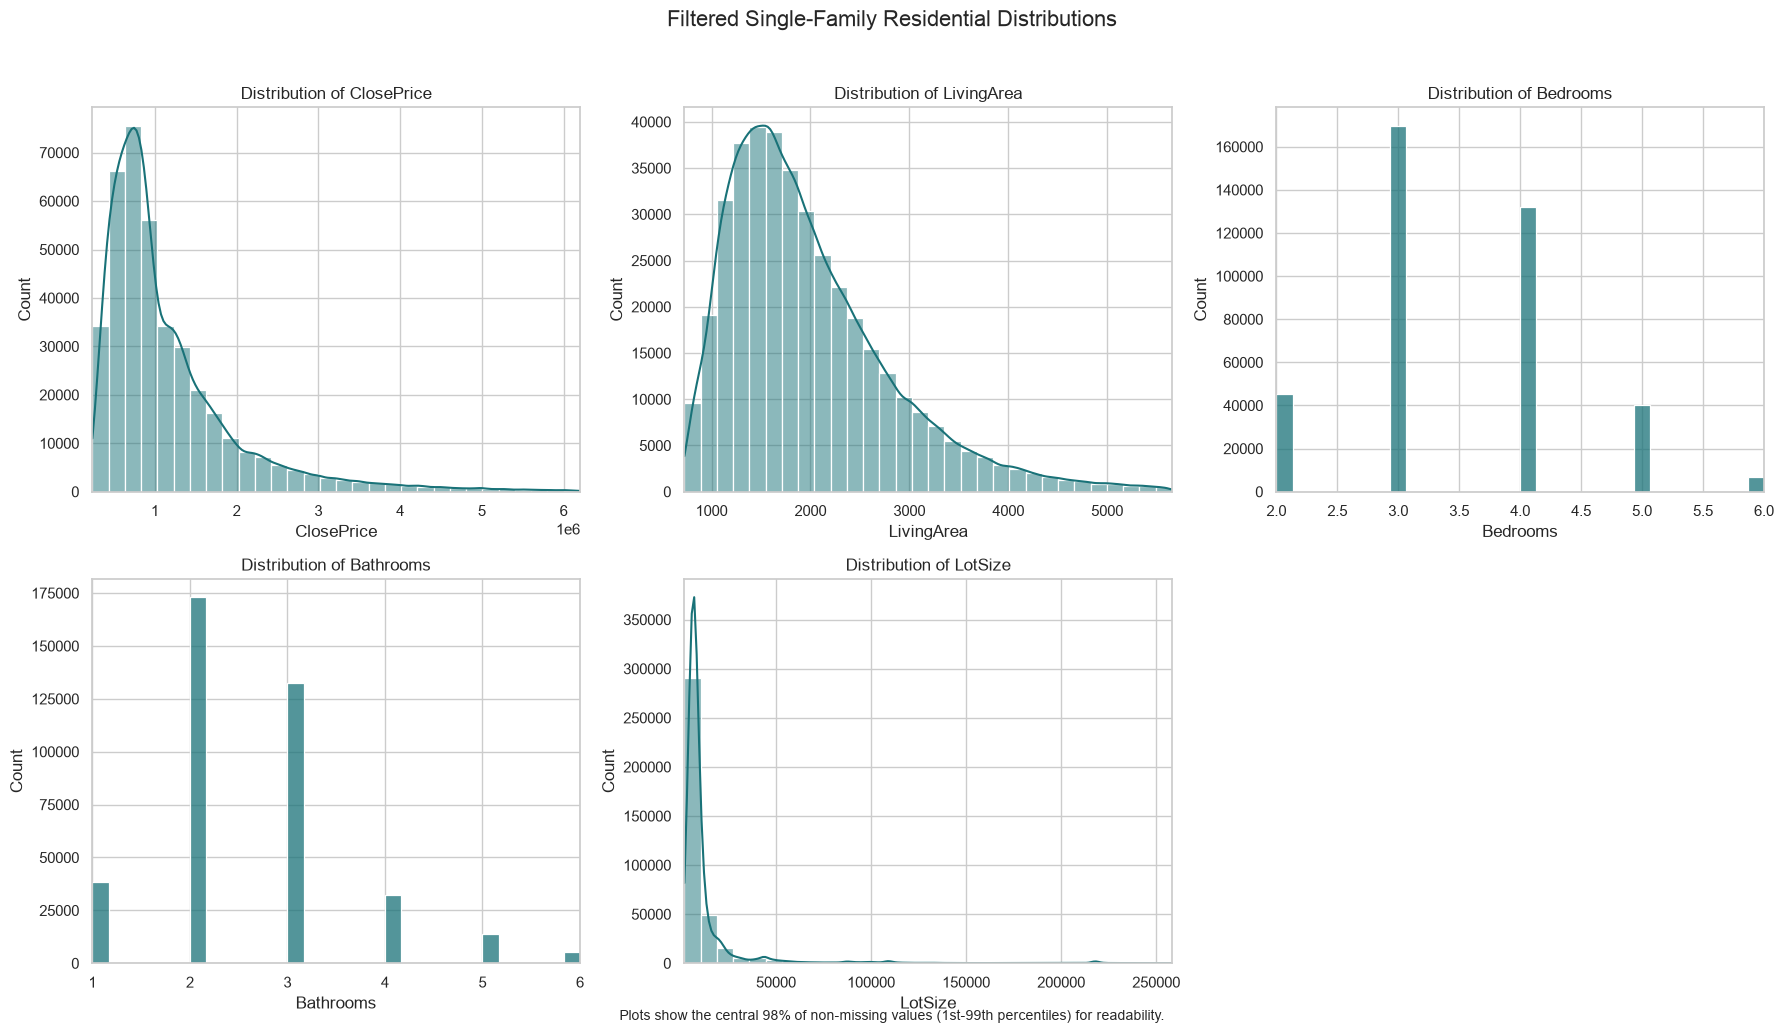

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()
for axis, column in zip(axes, NUMERIC_COLUMNS):
    values = filtered_df[column].dropna()
    lower, upper = values.quantile([0.01, 0.99])
    visible_values = values[values.between(lower, upper)]
    sns.histplot(x=visible_values, kde=column not in {'Bedrooms', 'Bathrooms'}, bins=30, ax=axis, color='#197278')
    axis.set_title(f'Distribution of {column}')
    axis.set_xlabel(column)
    axis.set_ylabel('Count')
    axis.set_xlim(lower, upper)
axes[-1].set_visible(False)
fig.suptitle('Filtered Single-Family Residential Distributions', fontsize=16, y=1.02)
fig.text(0.5, 0.01, 'Plots show the central 98% of non-missing values (1st-99th percentiles) for readability.', ha='center', fontsize=10)
fig.tight_layout()
plt.show()

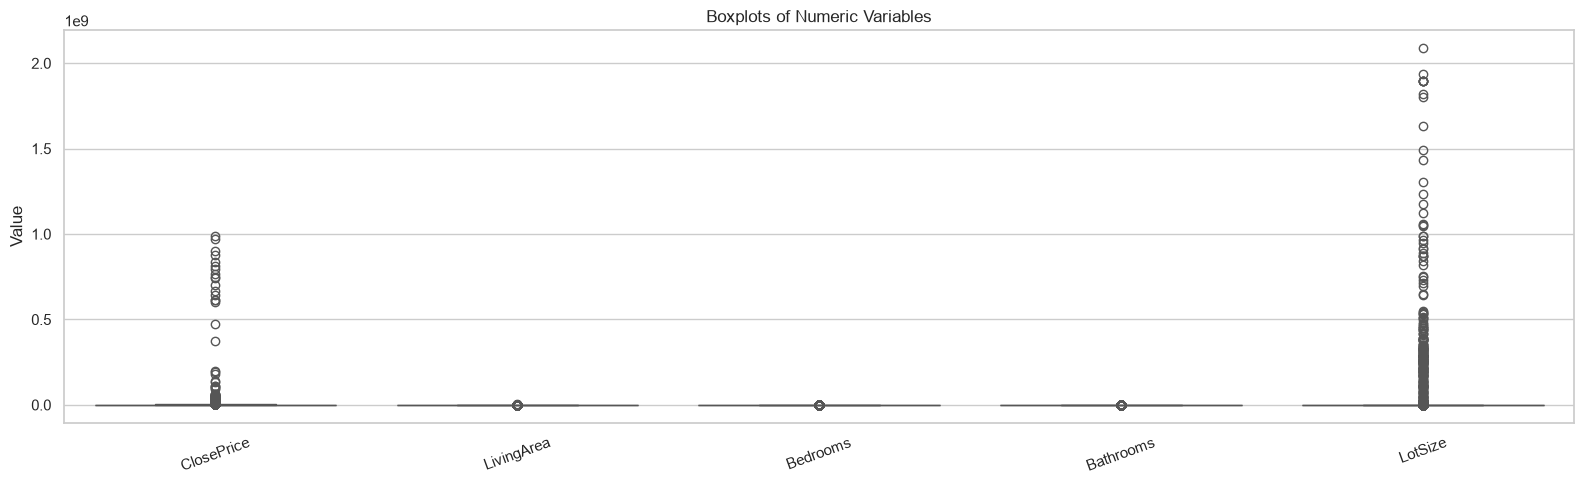

In [7]:
fig, axis = plt.subplots(figsize=(16, 5))
long_df = filtered_df[NUMERIC_COLUMNS].melt(var_name='variable', value_name='value').dropna()
sns.boxplot(data=long_df, x='variable', y='value', ax=axis, color='#e09f3e')
axis.set_title('Boxplots of Numeric Variables')
axis.set_xlabel('')
axis.set_ylabel('Value')
axis.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## Patterns and trends from the graphs

- **Distribution plots:** Close prices, living areas, and lot sizes are strongly right-skewed. Most single-family homes are concentrated at lower-to-moderate values, while a small number of unusually expensive, large, or large-lot properties create long upper tails. Bedrooms and bathrooms are much more concentrated: most homes have about 3-4 bedrooms and 2-3 bathrooms, so their discrete distributions are shown without KDE trendlines.
- **Boxplots:** The same pattern is especially clear from the many high-value outliers for ClosePrice, LivingArea, and LotSize. The bedroom and bathroom distributions are comparatively compact, although they also contain a few extreme records. Because these variables use very different scales, the boxplot is most useful for comparing spread and identifying outliers within each variable rather than comparing their absolute heights.